In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, roc_auc_score

print("Library berhasil dimuat!")

Library berhasil dimuat!


In [2]:
# 1. Memuat dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# 2. Membersihkan nilai kosong pada TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# 3. Menghapus kolom ID yang tidak relevan
df_model = df.drop('customerID', axis=1)

# 4. Enkod variabel target (Churn: Yes=1, No=0)
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

# 5. One-Hot Encoding untuk fitur kategorikal
df_encoded = pd.get_dummies(df_model, drop_first=True)

print("Bentuk Data Setelah Preprocessing:", df_encoded.shape)
print("Variabel Target:")
print(df_encoded['Churn'].value_counts())

Bentuk Data Setelah Preprocessing: (7043, 31)
Variabel Target:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [3]:
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print(f"Data Latih: {X_train.shape}, Data Uji: {X_test.shape}")

Data Latih: (4930, 30), Data Uji: (2113, 30)


In [4]:
# Model A: Dibiarkan tumbuh bebas (Overfit)
model_a = DecisionTreeClassifier(random_state=42)
model_a.fit(X_train, y_train)

# Evaluasi Data Latih vs Data Uji
acc_train_a = model_a.score(X_train, y_train)
acc_test_a = model_a.score(X_test, y_test)

print("--- MODEL A (OVERFIT) ---")
print(f"Akurasi Data Latih: {acc_train_a * 100:.2f}%")
print(f"Akurasi Data Uji  : {acc_test_a * 100:.2f}%\n")

print("Classification Report (Data Uji):")
print(classification_report(y_test, model_a.predict(X_test)))

--- MODEL A (OVERFIT) ---
Akurasi Data Latih: 99.80%
Akurasi Data Uji  : 73.12%

Classification Report (Data Uji):
              precision    recall  f1-score   support

           0       0.82      0.82      0.82      1552
           1       0.49      0.50      0.50       561

    accuracy                           0.73      2113
   macro avg       0.66      0.66      0.66      2113
weighted avg       0.73      0.73      0.73      2113



In [5]:
# Model B: Dipangkas untuk cegah overfitting (Pruned)
model_b = DecisionTreeClassifier(max_depth=3, random_state=42)
model_b.fit(X_train, y_train)

# Evaluasi Data Latih vs Data Uji
acc_train_b = model_b.score(X_train, y_train)
acc_test_b = model_b.score(X_test, y_test)

print("--- MODEL B (PRUNED) ---")
print(f"Akurasi Data Latih: {acc_train_b * 100:.2f}%")
print(f"Akurasi Data Uji  : {acc_test_b * 100:.2f}%\n")

print("Classification Report (Data Uji):")
print(classification_report(y_test, model_b.predict(X_test)))

--- MODEL B (PRUNED) ---
Akurasi Data Latih: 78.70%
Akurasi Data Uji  : 78.09%

Classification Report (Data Uji):
              precision    recall  f1-score   support

           0       0.79      0.95      0.86      1552
           1       0.70      0.31      0.43       561

    accuracy                           0.78      2113
   macro avg       0.74      0.63      0.65      2113
weighted avg       0.77      0.78      0.75      2113



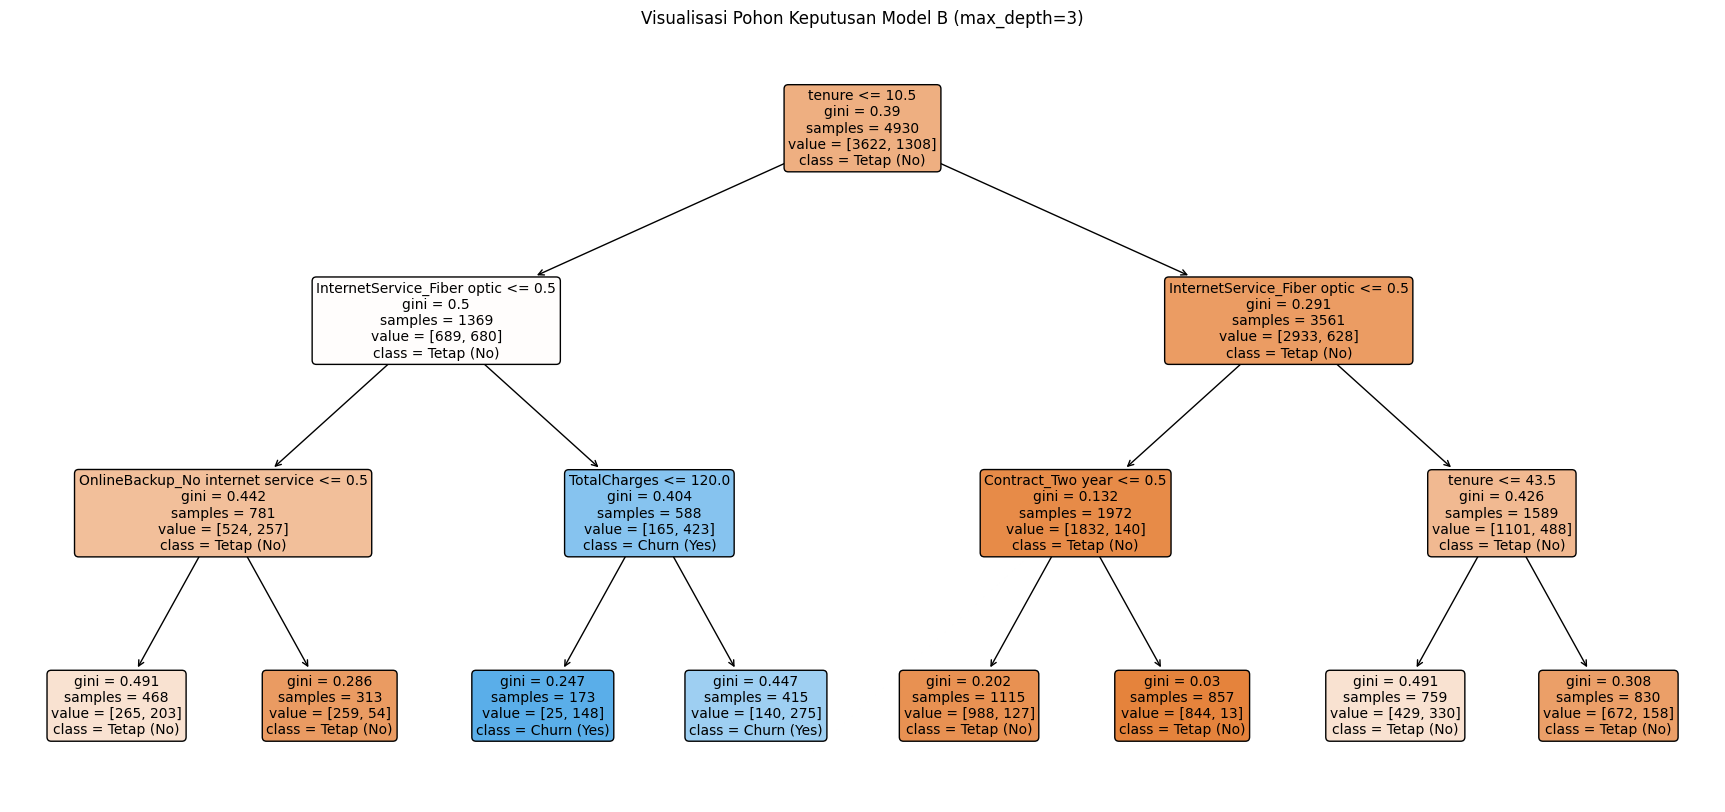

In [6]:
plt.figure(figsize=(22, 10))
plot_tree(
    model_b, 
    feature_names=X.columns, 
    class_names=['Tetap (No)', 'Churn (Yes)'], 
    filled=True, 
    rounded=True, 
    fontsize=10
)
plt.title("Visualisasi Pohon Keputusan Model B (max_depth=3)")
plt.savefig("pohon_keputusan.png", bbox_inches='tight', dpi=300)
plt.show()

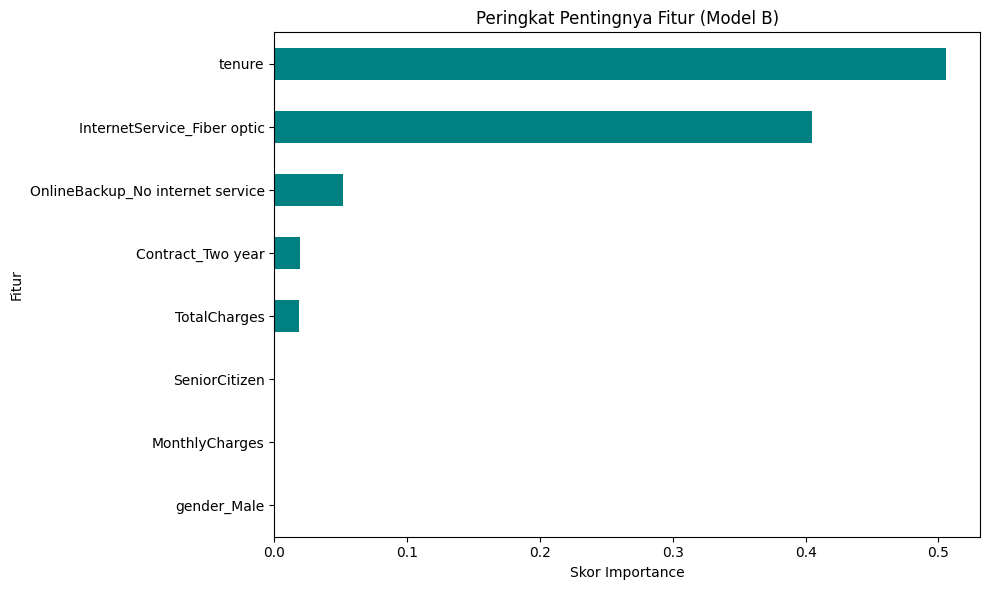

In [7]:
importances = model_b.feature_importances_
feat_importances = pd.Series(importances, index=X.columns)

plt.figure(figsize=(10, 6))
feat_importances.nlargest(8).plot(kind='barh', color='teal')
plt.title('Peringkat Pentingnya Fitur (Model B)')
plt.xlabel('Skor Importance')
plt.ylabel('Fitur')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()

In [8]:
# Simpan Model B dan daftar kolom X
joblib.dump(model_b, "model_dt_churn.joblib")
joblib.dump(X.columns.tolist(), "model_columns.joblib")

print("Model B dan daftar kolom berhasil disimpan!")

Model B dan daftar kolom berhasil disimpan!
